# Exploración de los datos de entrada del autoencoder

Plantilla del change `ae-reconstruccion` (tarea 8.3). Corre en JupyterLab del Space
`sinca-dev`, con el rol del Space. **Nivel 1: sin TensorFlow.**

Explora la grilla horaria que consume el AE: cobertura y huecos por serie y canal,
ventanas que sobreviven según `L`, rangos tras la transformación, y el efecto de la
interpolación de ≤ 6 h y del recorte de auxiliares.

Convención: notebooks scratch, no fuente de verdad; se versionan sin outputs (`git add -f`).

Gráficos con matplotlib (no Plotly: en el Space las figuras interactivas tardan demasiado).

In [1]:
import sys, pathlib
# Raíz de importación del pipeline: el notebook vive en notebooks/ (o en la raíz del repo).
_here = pathlib.Path.cwd()
PIPELINE = next(p for p in (_here / "pipeline", _here.parent / "pipeline") if p.exists())
sys.path.insert(0, str(PIPELINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analysis import load
from features.build import load_validated
from ae import data as aed
from ae import dmd as dmdm
from ae import metrics as aem

BUCKET_DATA = "sinca-data"
# Credenciales: el rol del Space (sinca-dev-role) las provee; no escribir claves aquí.

## 1. Cargar datos validados y armar la grilla

In [2]:
validated = load_validated(BUCKET_DATA)  # S3 real; en local usar local_dir=...
grid = aed.build_grid(validated["sinca"], validated["open_meteo"], validated["feriados"])
print("horas:", len(grid.index), "| desde", grid.index.min(), "hasta", grid.index.max())

horas: 50471 | desde 2021-01-01 01:00:00-03:00 hasta 2026-10-04 23:00:00-03:00


## 2. Cobertura y huecos por canal
Fracción de horas medidas (real), interpoladas (≤ 6 h) y huecos largos (> 6 h).

In [3]:
rows = []
for col in grid.mp.columns:
    real = grid.mp_real[col].mean()
    long_gap = grid.mp[col].isna().mean()
    rows.append({"grupo": "mp", "canal": col, "real": real, "interpolado": 1 - real - long_gap, "hueco_largo": long_gap})
for col in grid.aux.columns:
    real = grid.aux_real[col].mean()
    long_gap = grid.aux[col].isna().mean()
    rows.append({"grupo": "aux", "canal": col, "real": real, "interpolado": 1 - real - long_gap, "hueco_largo": long_gap})
coverage = pd.DataFrame(rows)
display(coverage.round(3))

,grupo,canal,real,interpolado,hueco_largo
0,mp,pm25_padre_las_casas_ii,0.950,0.024,0.026
1,mp,pm25_nielol,0.986,0.006,0.008
2,mp,pm25_las_encinas,0.969,0.005,0.027
3,mp,pm10_padre_las_casas_ii,0.953,0.024,0.023
4,mp,pm10_nielol,0.985,0.006,0.008
5,mp,pm10_las_encinas,0.966,0.005,0.029
6,aux,pres_padre_las_casas_ii,0.953,0.022,0.025
7,aux,wspd_padre_las_casas_ii,0.949,0.022,0.029
8,aux,rain_padre_las_casas_ii,0.953,0.022,0.025
9,aux,pres_nielol,0.986,0.006,0.008


## 3. Ventanas que sobreviven según L (regla de descarte por huecos > 6 h)

,L,particion,muestras
0,24,train,43051
1,24,test,1999
2,72,train,39414
3,72,test,1761
4,168,train,33669
5,168,test,1377


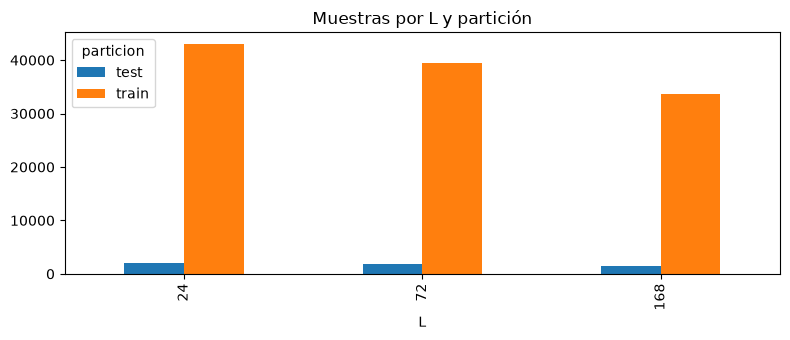

In [4]:
spans = aed.holdout_spans(grid.index)
survival = aed.survival_counts(grid, (24, 72, 168), spans)
display(survival)
ax = survival.pivot(index="L", columns="particion", values="muestras").plot.bar(figsize=(8, 3.5), title="Muestras por L y partición")
plt.tight_layout()
plt.show()

## 4. Rangos por canal tras la transformación (fit de normalización solo en train)

In [5]:
train_mask = np.zeros(len(grid.index), dtype=bool)
train_mask[spans["train"][0]:spans["train"][1]] = True
norm = aed.fit_normalizer(grid, train_mask)
ng = aed.apply_normalizer(grid, norm)
ranges = aed.range_report(ng, real_rows=train_mask)
display(ranges.round(3))

,grupo,canal,min,p01,p50,p99,max,frac_recortada
0,mp,pm25_padre_las_casas_ii,-2.213,-1.636,-0.078,2.519,3.372,0.000
1,mp,pm25_nielol,-2.106,-1.457,-0.158,2.631,3.904,0.000
2,mp,pm25_las_encinas,-2.261,-1.636,-0.099,2.576,3.702,0.000
3,mp,pm10_padre_las_casas_ii,-3.705,-2.469,-0.085,2.767,3.872,0.000
4,mp,pm10_nielol,-3.698,-2.840,0.011,2.653,4.564,0.000
5,mp,pm10_las_encinas,-3.466,-2.695,-0.028,2.630,3.907,0.000
6,aux,pres_padre_las_casas_ii,-5.253,-2.630,-0.018,2.451,3.748,0.000
7,aux,wspd_padre_las_casas_ii,-1.418,-1.364,-0.095,2.140,3.383,0.000
8,aux,rain_padre_las_casas_ii,-0.212,-0.212,-0.212,5.306,19.723,0.010
9,aux,pres_nielol,-20.747,-2.604,-0.054,2.375,3.640,0.001


## 5. Efecto de la interpolación ≤ 6 h y del recorte de auxiliares
Se compara la serie cruda con la llenada en un tramo con huecos.

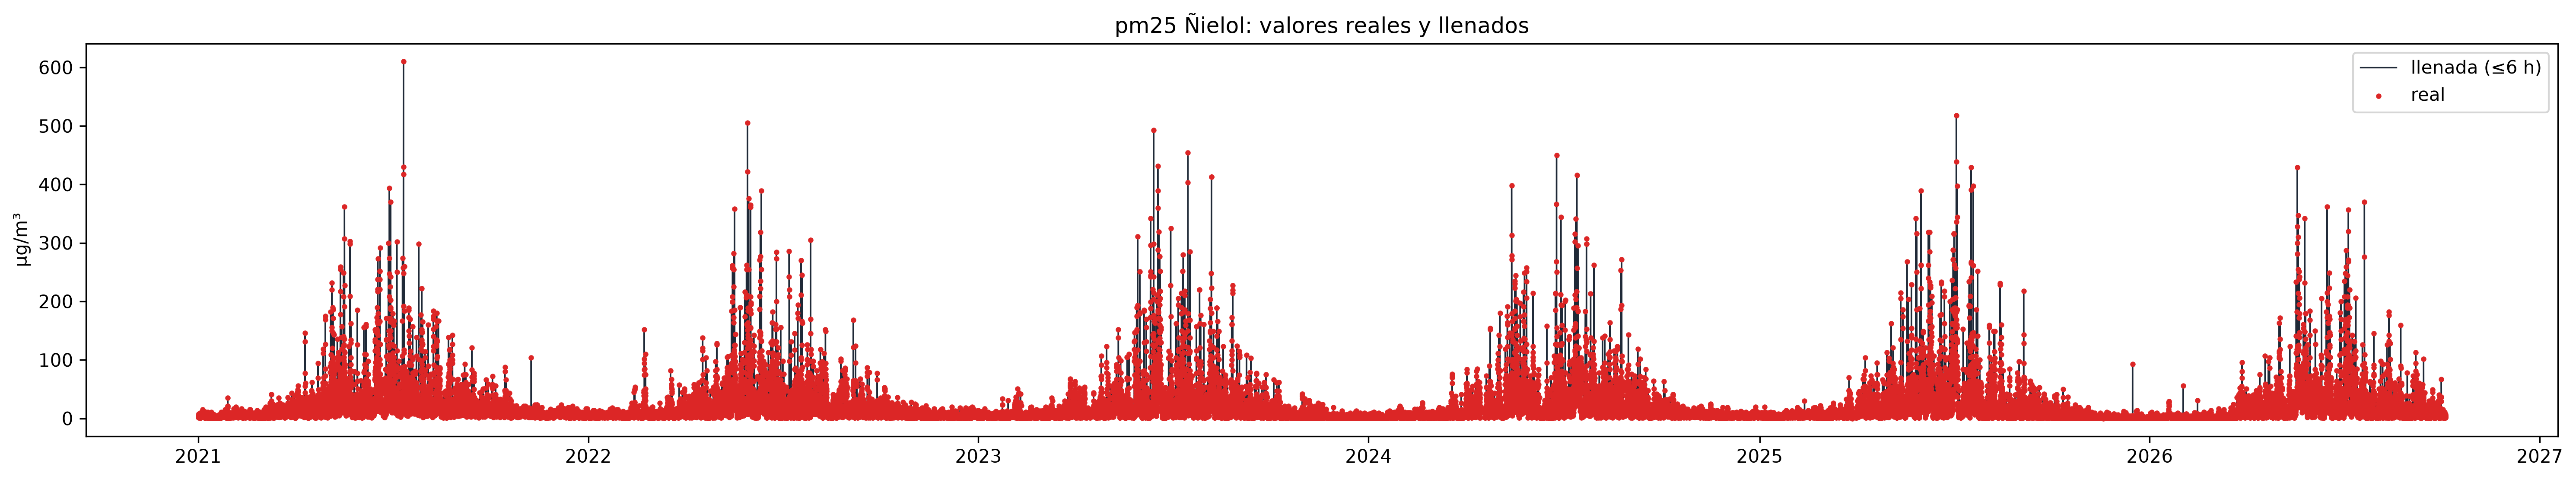

In [7]:
col = "pm25_nielol"
s = grid.mp[col]
real_mask = grid.mp_real[col].to_numpy()
fig, ax = plt.subplots(figsize=(20, 3.8), dpi=300)
ax.plot(grid.index, s, lw=0.8, color="#1f2937", label="llenada (≤6 h)")
ax.scatter(grid.index[real_mask], s[real_mask], s=4, color="#dc2626", label="real", zorder=3)
ax.set_title("pm25 Ñielol: valores reales y llenados")
ax.set_ylabel("µg/m³")
ax.legend()
fig.tight_layout()
plt.show()